In [12]:
from dotenv import load_dotenv
from typing import TypedDict, Annotated
from langgraph.graph import StateGraph , START, END
from langgraph.graph.message  import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langchain_core.tools import tool
from langgraph.checkpoint.memory import MemorySaver
load_dotenv()
memory = MemorySaver()

In [13]:
from langchain.chat_models import init_chat_model

In [14]:
@tool
def get_stock_price(symbol: str) -> float:
    '''
    Returns the stock price of a given symbol
    :param symbol:stock symbol
    :return:current stock price
    '''

    return{
        "AMZN": 106,
        "MNST":700
    }.get(symbol,0.0)

tools = [get_stock_price]


llm = init_chat_model(
    model="openai/gpt-oss-120b",
    model_provider="groq",
    temperature=0,
)
llm_with_tools = llm.bind_tools(tools)

In [21]:
class State(TypedDict):
    messages: Annotated[list, add_messages]

def chatbot(state: State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

builder = StateGraph(State)

builder.add_node("chatbot", chatbot)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "chatbot")

builder.add_conditional_edges(
    "chatbot",
    tools_condition
)
builder.add_edge("tools", "chatbot")
builder.add_edge( "chatbot",END)

graph = builder.compile(checkpointer=memory)

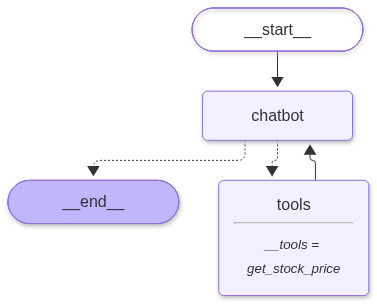

In [22]:
from IPython.display import Image,display

display(Image(graph.get_graph().draw_mermaid_png()))

In [23]:
config = {'configurable':{'thread_id': '1'}}

state= graph.invoke({"messages": [{"role":"user" , "content":"what is the current stock price of AMZN "}]},config=config)

print(state["messages"][-1].content)

The current price of Amazon (AMZN) is **$106** per share.


In [24]:
config = {'configurable':{'thread_id': '1'}}

msg = "I want to buy 20 AMZN stocks using current price. Then 15 MNST.what will be the total cost "

state= graph.invoke({"messages": [{"role":"user" , "content":msg}]},config=config)

print(state["messages"][-1].content)

Here’s the cost breakdown based on the current prices:

| Stock | Quantity | Price per Share | Sub‑total |
|-------|----------|----------------|-----------|
| AMZN  | 20       | $106           | 20 × $106 = **$2,120** |
| MNST  | 15       | $700           | 15 × $700 = **$10,500** |

**Total cost:** $2,120 + $10,500 = **$12,620**.


In [25]:
msg2 = "I want to buy 20 more AMZN stocks and add it to the previous total cost "

state= graph.invoke({"messages": [{"role":"user" , "content":msg2}]},config=config)

print(state["messages"][-1].content)

Sure! At the current price of **$106 per AMZN share**, buying 20 more shares will cost:

- **20 × $106 = $2,120**

Adding that to your previous total of **$12,620** gives:

**$12,620 + $2,120 = $14,740**

So the updated total cost for all the stocks you’ve planned to purchase is **$14,740**.
